# FinTrust Digital Bank: Week 4 Final Analysis Notebook
**Track:** Data Analytics | **Author:** Yawa Jacqueline GBEDEVI | **Programme:** AnalystLab Africa

This notebook is the final, reproducible version of the Python analysis. It does four things:

1. Loads the cleaned data and runs **data quality tests** (Part A).
2. **Reconciles every KPI of the Power BI dashboard** with an independent calculation (Part A and C).
3. Keeps the **five exploratory charts of Week 3** (Step 4), with their original conclusions.
4. **Validates six analytical findings** with a second method (Part E).
5. Saves the charts used in the final report and a JSON file with all results.

**How to run it:** install the packages from `requirements.txt`, keep the folder structure (`data/`, `notebooks/`, `figures/`, `docs/`) and run all cells from top to bottom. Random operations use a fixed seed, so a second run gives the same numbers.

All data is synthetic. `Risk_Review_Flag` is an educational label, not a fraud determination.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

SEED = 42
rng = np.random.default_rng(SEED)
DATA, FIG, DOCS = Path("../data"), Path("../figures"), Path("../docs")
FIG.mkdir(exist_ok=True); DOCS.mkdir(exist_ok=True)

GOLD, NAVY, GREY, RED = "#BFA14F", "#2E3A87", "#8C8C8C", "#C0392B"
sns.set_theme(style="whitegrid", font_scale=1.0)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
R = {}   # all results are stored here and saved at the end

## Part A. Step 1: Load the data and run the data quality tests

In [2]:
cust = pd.read_csv(DATA / "FinTrust_Customer_Data.csv")
tx = pd.read_csv(DATA / "FinTrust_Transaction_Data_Clean.csv", parse_dates=["Transaction_DateTime"])
df = tx.merge(cust, on="Customer_ID", how="left", validate="many_to_one")

df["flag"]   = (df.Risk_Review_Flag == "Yes").astype(int)
df["intl"]   = (df.International_Transaction == "Yes").astype(int)
df["ok"]     = (df.Transaction_Status == "Successful").astype(int)
df["failed"] = (df.Transaction_Status == "Failed").astype(int)
q1, q3 = df.Amount_NGN.quantile([.25, .75])
THR = q3 + 1.5 * (q3 - q1)                      # outlier threshold (IQR rule)
df["high"] = (df.Amount_NGN > THR).astype(int)
df["band"] = pd.cut(df.Amount_NGN, [0, 10000, 50000, THR, np.inf],
                    labels=["<10k", "10k-50k", "50k-118k", ">118k"], right=False)

tests = [
    ("Transaction rows", 12000, len(tx)),
    ("Unique Transaction_ID", 12000, tx.Transaction_ID.nunique()),
    ("Customer rows", 1500, len(cust)),
    ("Unique Customer_ID", 1500, cust.Customer_ID.nunique()),
    ("Transactions without a matching customer", 0, int(df.Customer_Segment.isna().sum())),
    ("Amounts <= 0", 0, int((df.Amount_NGN <= 0).sum())),
    ("Missing values left (any column)", 0, int(tx.isna().sum().sum())),
    ("Rows with Device_Type or Location = Not Provided", 188,
        int(((tx.Device_Type == "Not Provided") | (tx.Location == "Not Provided")).sum())),
    ("First date", "2026-01-01", str(tx.Transaction_DateTime.min().date())),
    ("Last date", "2026-03-31", str(tx.Transaction_DateTime.max().date())),
    ("Status values outside the 4 expected", 0,
        int((~tx.Transaction_Status.isin(["Successful", "Failed", "Reversed", "Pending"])).sum())),
    ("Flag / international values outside Yes-No", 0,
        int((~tx.Risk_Review_Flag.isin(["Yes", "No"])).sum() + (~tx.International_Transaction.isin(["Yes", "No"])).sum())),
]
dq = pd.DataFrame(tests, columns=["Test", "Expected", "Actual"])
dq["Result"] = np.where(dq.Expected.astype(str) == dq.Actual.astype(str), "PASS", "FAIL")
print(dq.to_string(index=False))
assert (dq.Result == "PASS").all(), "A data quality test failed"
R["data_quality_tests"] = dq.to_dict("records")
R["outlier_threshold"] = round(float(THR), 2)
print("\nOutlier threshold (Q3 + 1.5 x IQR):", round(THR, 2))

                                            Test   Expected     Actual Result
                                Transaction rows      12000      12000   PASS
                           Unique Transaction_ID      12000      12000   PASS
                                   Customer rows       1500       1500   PASS
                              Unique Customer_ID       1500       1500   PASS
        Transactions without a matching customer          0          0   PASS
                                    Amounts <= 0          0          0   PASS
                Missing values left (any column)          0          0   PASS
Rows with Device_Type or Location = Not Provided        188        188   PASS
                                      First date 2026-01-01 2026-01-01   PASS
                                       Last date 2026-03-31 2026-03-31   PASS
            Status values outside the 4 expected          0          0   PASS
      Flag / international values outside Yes-No          0     

## Part A. Step 2: Two data quality observations that were not in the Week 2 report
Both are about how the synthetic data was generated. They do not change any KPI, but they limit what can be concluded.

In [3]:
known = df[df.Device_Type != "Not Provided"]
atm = known[known.Channel == "ATM"]
share_non_atm_device = (atm.Device_Type != "ATM Terminal").mean()
p_dev = stats.chi2_contingency(pd.crosstab(known.Channel, known.Device_Type))[1]
loc_match = (df.Location == df.City).mean()

print(f"ATM transactions recorded with a device other than 'ATM Terminal': {share_non_atm_device:.1%}")
print(f"Channel and Device_Type are independent in this data (chi-square p = {p_dev:.3f})")
print(f"Transaction Location equals the customer's home City in only {loc_match:.1%} of transactions")
R["device_channel"] = {"atm_non_atm_device_share": round(float(share_non_atm_device), 4), "p": round(float(p_dev), 3)}
R["location_equals_city_share"] = round(float(loc_match), 4)

# Does the 'Not Provided' group behave differently? (decision from Week 2: keep, do not delete)
df["np"] = ((df.Device_Type == "Not Provided") | (df.Location == "Not Provided")).astype(int)
p_np_flag = stats.chi2_contingency(pd.crosstab(df.np, df.flag))[1]
p_np_ok = stats.chi2_contingency(pd.crosstab(df.np, df.ok))[1]
print(f"'Not Provided' rows vs the others: flag rate p = {p_np_flag:.2f}, success rate p = {p_np_ok:.2f}")
R["not_provided_effect"] = {"p_flag": round(float(p_np_flag), 3), "p_success": round(float(p_np_ok), 3)}

ATM transactions recorded with a device other than 'ATM Terminal': 89.9%
Channel and Device_Type are independent in this data (chi-square p = 0.146)
Transaction Location equals the customer's home City in only 12.7% of transactions
'Not Provided' rows vs the others: flag rate p = 0.12, success rate p = 0.52


## Part A and C. Step 3: Reconcile the Power BI dashboard with an independent calculation
Every value below is the value shown on a dashboard card or table (final version of the dashboard). The notebook recomputes it from the data. A difference would show a wrong DAX measure, a filter problem or an import problem (for example a decimal comma).

In [4]:
mobile = df[df.Channel == "Mobile App"]
dash = [  # (visual, dashboard value, computed value, tolerance)
    ("Home: Total Customers", 1500, cust.Customer_ID.nunique(), 0),
    ("Home: Total Transactions", 12000, len(df), 0),
    ("Home: Tx per Day", 133.33, len(df) / df.Transaction_DateTime.dt.date.nunique(), 0.005),
    ("Home: Total Value (M NGN)", 560.48, df.Amount_NGN.sum() / 1e6, 0.005),
    ("Home: Avg Transaction Value (K NGN)", 46.71, df.Amount_NGN.mean() / 1e3, 0.005),
    ("Home: Median Transaction Value (K NGN)", 10.31, df.Amount_NGN.median() / 1e3, 0.005),
    ("Customers: Dormant Rate (%)", 7.13, (cust.Account_Status == "Dormant").mean() * 100, 0.005),
    ("Customers: Tx per Customer", 8.00, len(df) / len(cust), 0.005),
    ("Customers: Premium median (NGN)", 10218.87, df[df.Customer_Segment == "Premium"].Amount_NGN.median(), 0.01),
    ("Transaction: Success Rate (%)", 90.47, df.ok.mean() * 100, 0.005),
    ("Transaction: Failure Rate (%)", 5.25, df.failed.mean() * 100, 0.005),
    ("Transaction: Failed Value (M NGN)", 24.83, df[df.failed == 1].Amount_NGN.sum() / 1e6, 0.005),
    ("Transaction: Mobile App failed tx", 296, int(mobile.failed.sum()), 0),
    ("Transaction: Mobile App failed value (NGN)", 13086618.35, mobile[mobile.failed == 1].Amount_NGN.sum(), 0.01),
    ("Transaction: Mobile App transactions", 5102, len(mobile), 0),
    ("Risk: Risk Review Rate (%)", 19.60, df.flag.mean() * 100, 0.005),
    ("Risk: Flag Rate International (%)", 36.88, df[df.intl == 1].flag.mean() * 100, 0.005),
    ("Risk: Flag Rate Domestic (%)", 18.88, df[df.intl == 0].flag.mean() * 100, 0.005),
    ("Risk: International Tx", 480, int(df.intl.sum()), 0),
    ("Risk: Flag rate >118k international (%)", 48.15, df[(df.band == ">118k") & (df.intl == 1)].flag.mean() * 100, 0.005),
    ("Customers: Preferred=USSD, actual Mobile App (%)", 41.75,
        (df[df.Preferred_Channel == "USSD"].Channel == "Mobile App").mean() * 100, 0.005),
]
rec = pd.DataFrame(dash, columns=["Dashboard visual", "Dashboard", "Notebook", "Tol"])
rec["Notebook"] = rec.Notebook.astype(float).round(2)
rec["Result"] = np.where((rec.Dashboard - rec.Notebook).abs() <= rec.Tol + 1e-9, "PASS", "FAIL")
print(rec.drop(columns="Tol").to_string(index=False))
print("\nPassed:", int((rec.Result == "PASS").sum()), "of", len(rec))
R["dashboard_reconciliation"] = rec.drop(columns="Tol").to_dict("records")

                                Dashboard visual   Dashboard    Notebook Result
                           Home: Total Customers     1500.00     1500.00   PASS
                        Home: Total Transactions    12000.00    12000.00   PASS
                                Home: Tx per Day      133.33      133.33   PASS
                       Home: Total Value (M NGN)      560.48      560.48   PASS
             Home: Avg Transaction Value (K NGN)       46.71       46.71   PASS
          Home: Median Transaction Value (K NGN)       10.31       10.31   PASS
                     Customers: Dormant Rate (%)        7.13        7.13   PASS
                      Customers: Tx per Customer        8.00        8.00   PASS
                 Customers: Premium median (NGN)    10218.87    10218.87   PASS
                   Transaction: Success Rate (%)       90.47       90.47   PASS
                   Transaction: Failure Rate (%)        5.25        5.25   PASS
               Transaction: Failed Value

## Step 4. Exploratory charts from Week 3 (kept)
These are the five charts built in Week 3, with their original code and conclusions. They are kept in the final notebook because they are the exploratory part of the analysis. Each one is then tested again with a second method in the validation sections below.

| Chart | Question | Week 2 link | Re-tested in |
|---|---|---|---|
| 1 | Is Premium really the lowest segment? | Finding 1 | Validation 1 |
| 2 | Is the Mobile App really the least reliable channel? | Finding 2 | Validation 2 |
| 3 | Is activity growing or falling over the quarter? | Monthly trend | Validation 6 |
| 4 | Do international and high amounts increase the flag rate? | Finding 4 | Validation 4 |
| 5 | Does the transaction type matter for the flag rate? | New in Week 3 | Validation 4 |

The charts are saved in `figures/week3/`. Only the file paths were changed from the Week 3 version, so that the notebook runs from the project folders.

In [5]:
(FIG / "week3").mkdir(exist_ok=True)

### Chart 1: Average and median amount by segment (Finding 1)
Week 2 said Premium had the lowest average. Here the average is shown next to the **median** (the middle value), which is less affected by a few very large amounts.

                     mean   median
Customer_Segment                  
Everyday          46325.0   9929.0
Premium           45638.0  10219.0
SME               49116.0  11627.0
Student           46953.0  10531.0


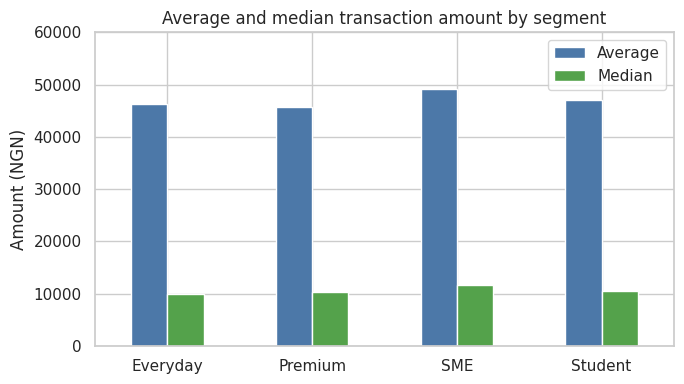

In [6]:
by_segment = df.groupby("Customer_Segment")["Amount_NGN"].agg(["mean", "median"]).round(0)
print(by_segment)

by_segment.plot(kind="bar", figsize=(7, 4), color=["#4C78A8", "#54A24B"])
plt.title("Average and median transaction amount by segment")
plt.ylabel("Amount (NGN)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 60000)
plt.legend(["Average", "Median"], loc="upper right")
plt.tight_layout()
plt.savefig(FIG / "week3" / "chart1_segments.png", dpi=150)
plt.show()

**Reading.** On the average, Premium is the lowest (45,638). On the median, Premium (10,219) is higher than Everyday (9,929). The ranking changes depending on the measure, and the gaps are small. **Finding 1 is revised:** the four segments behave in a similar way, and the data does not show that Premium customers transact less.

### Chart 2: Failure rate by channel (Finding 2)
The failure rate is the share of transactions with status `Failed`. The number of failed transactions is added, because a small rate on a large channel still affects many customers.

            transactions  failed  failure_rate_%
Channel                                         
Mobile App          5102     296            5.80
USSD                 889      48            5.40
POS                 2393     125            5.22
Web                 1869      88            4.71
ATM                 1747      73            4.18


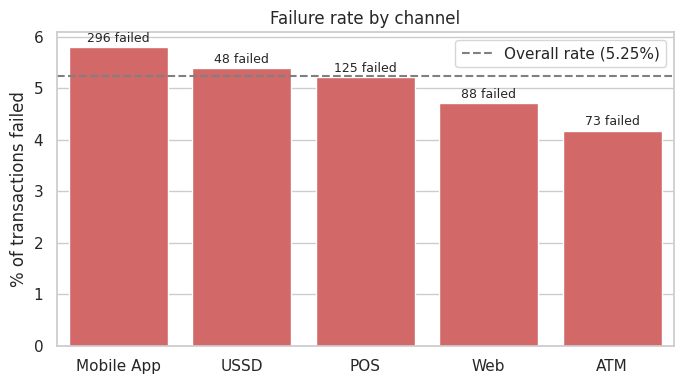

In [7]:
df["is_failed"] = (df["Transaction_Status"] == "Failed").astype(int)

channels = df.groupby("Channel").agg(transactions=("is_failed", "size"), failed=("is_failed", "sum"))
channels["failure_rate_%"] = (channels["failed"] / channels["transactions"] * 100).round(2)
channels = channels.sort_values("failure_rate_%", ascending=False)
print(channels)

overall = df["is_failed"].mean() * 100

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=channels.index, y=channels["failure_rate_%"], color="#E45756")
ax.axhline(overall, color="grey", linestyle="--", label=f"Overall rate ({overall:.2f}%)")
for i, (rate, n) in enumerate(zip(channels["failure_rate_%"], channels["failed"])):
    ax.text(i, rate + 0.1, f"{n} failed", ha="center", fontsize=9)
plt.title("Failure rate by channel")
plt.ylabel("% of transactions failed")
plt.xlabel("")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "week3" / "chart2_channels.png", dpi=150)
plt.show()

**Reading.** The Mobile App has the highest rate (5.80%) and by far the most failed transactions (296), because it carries 42.5% of all traffic. The other channels are between 4.2% and 5.4%, so the gaps in rate are small. **Finding 2 is nuanced:** the Mobile App is where the largest number of customers is affected, but the data does not prove that it is much less reliable than the other channels.

### Chart 3: Transactions per day (trend)
Week 2 compared monthly totals. February looked lower, but it has fewer days. Here activity is shown **per day**, with a 7-day average to smooth the line.

Average transactions per day: 133.3


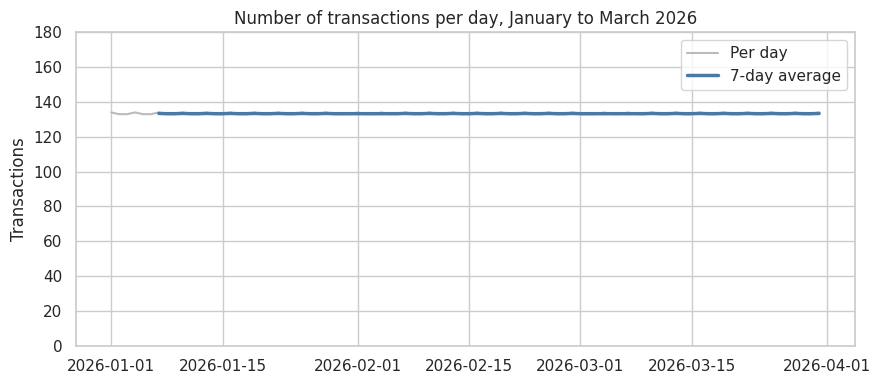

In [8]:
df["Transaction_DateTime"] = pd.to_datetime(df["Transaction_DateTime"])
df["date"] = df["Transaction_DateTime"].dt.date

per_day = df.groupby("date").size()
per_day.index = pd.to_datetime(per_day.index)
average_7_days = per_day.rolling(7).mean()

print("Average transactions per day:", round(per_day.mean(), 1))

plt.figure(figsize=(9, 4))
plt.plot(per_day.index, per_day, color="#BBBBBB", label="Per day")
plt.plot(average_7_days.index, average_7_days, color="#4C78A8", linewidth=2.5, label="7-day average")
plt.ylim(0, 180)
plt.title("Number of transactions per day, January to March 2026")
plt.ylabel("Transactions")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "week3" / "chart3_trend.png", dpi=150)
plt.show()

**Reading.** The line is flat at about 133 transactions per day for the whole quarter. The lower February total in Week 2 only came from the shorter month (28 days), and there is no real dip or rebound. Three months is also too short to talk about growth. Note: a perfectly flat line is unusual in real banking data. It is a limit of the synthetic dataset.

### Chart 4: Flag rate by amount band, domestic versus international (Finding 4)
The flag rate is the share of transactions with `Risk_Review_Flag = Yes`. The amounts are split into 4 bands, using the 117,923 NGN outlier threshold from the Data Quality Report.

             Domestic  International
amount_band                         
Under 10k        16.9           34.1
10k-50k          16.9           40.7
50k-118k         18.2           29.2
Over 118k        31.6           48.1


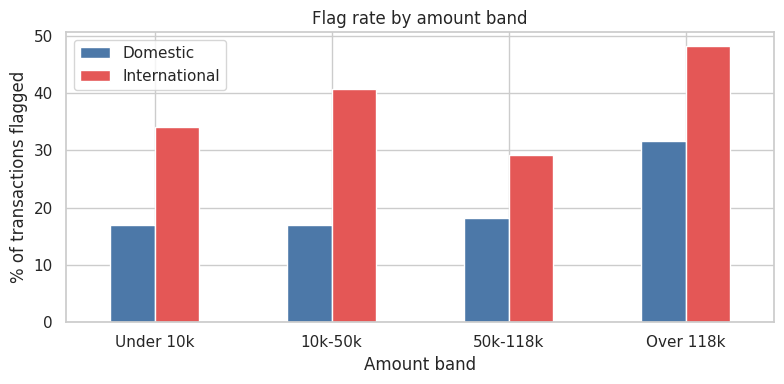

In [9]:
df["is_flagged"] = (df["Risk_Review_Flag"] == "Yes").astype(int)

df["amount_band"] = pd.cut(df["Amount_NGN"],
                           bins=[0, 10000, 50000, 117922.86, float("inf")],
                           labels=["Under 10k", "10k-50k", "50k-118k", "Over 118k"])

by_band = df.pivot_table(index="amount_band", columns="International_Transaction",
                         values="is_flagged", aggfunc="mean", observed=True) * 100
by_band.columns = ["Domestic", "International"]
print(by_band.round(1))

by_band.plot(kind="bar", figsize=(8, 4), color=["#4C78A8", "#E45756"])
plt.title("Flag rate by amount band")
plt.ylabel("% of transactions flagged")
plt.xlabel("Amount band")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.savefig(FIG / "week3" / "chart4_flag_by_band.png", dpi=150)
plt.show()

**Reading.** In every amount band, international transactions are flagged much more often than domestic ones (between 1.5 and 2.4 times more). The amount also matters: above 118k, even domestic transactions reach about 32%. The highest rate (48%) combines both. **Finding 4 is confirmed.** Caution: there are few international transactions (480 in total), so each international bar is less precise.

### Chart 5: Flag rate by transaction type (new in Week 3)
Is the flag rate the same for every type of transaction?

Transaction_Type
Transfer           28.5
Cash Withdrawal    25.3
Deposit            16.2
Airtime/Data       15.2
Card Purchase      13.0
Bill Payment       12.8
Name: is_flagged, dtype: float64


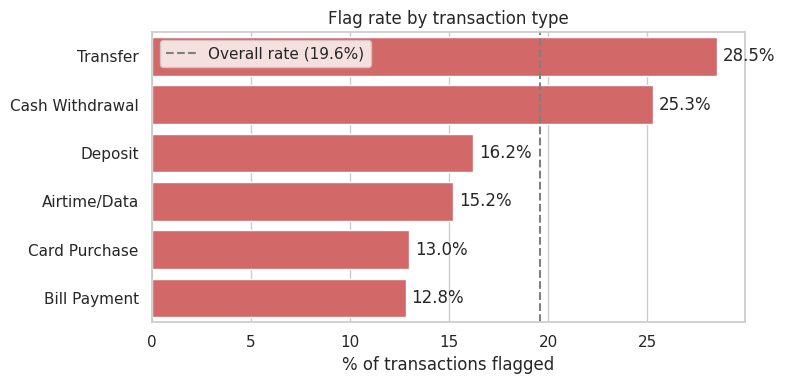

In [10]:
by_type = (df.groupby("Transaction_Type")["is_flagged"].mean() * 100).sort_values(ascending=False).round(1)
print(by_type)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=by_type.values, y=by_type.index, color="#E45756")
ax.axvline(df["is_flagged"].mean() * 100, color="grey", linestyle="--", label="Overall rate (19.6%)")
for i, v in enumerate(by_type.values):
    ax.text(v + 0.3, i, f"{v}%", va="center")
plt.title("Flag rate by transaction type")
plt.xlabel("% of transactions flagged")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "week3" / "chart5_flag_by_type.png", dpi=150)
plt.show()

**Reading.** Transfer (28.5%) and Cash Withdrawal (25.3%) are flagged about twice as often as Card Purchase, Bill Payment, Deposit or Airtime/Data (about 13 to 16%). Part of this could come from larger amounts, but in a separate check by amount band, the gap remained inside each band. Transaction type is therefore a **third factor** linked to the flag, in addition to international status and amount. This is new compared with Week 2.

### Optional check from Week 3: do the differences come from chance?
A p-value **below 0.05** means the difference is unlikely to be only chance.

In [11]:
# 1. Do amounts differ between segments?
groups = [g["Amount_NGN"] for _, g in df.groupby("Customer_Segment")]
print("Segments (amounts), p-value:", round(stats.kruskal(*groups).pvalue, 2))

# 2. Does the failure rate differ between channels?
table = pd.crosstab(df["Channel"], df["is_failed"])
print("Channels (failure rate), p-value:", round(stats.chi2_contingency(table)[1], 3))

Segments (amounts), p-value: 0.2
Channels (failure rate), p-value: 0.081


**Reading.** Both p-values are above 0.05 (about 0.20 and 0.08). The differences between segments and between channels could come from chance, which supports revising Finding 1 and nuancing Finding 2.

## Part E. Validation 1: Premium customers and transaction value
**Finding to validate:** the four segments behave in a similar way (the Week 2 claim that Premium is lowest was revised in Week 3).
**New method:** bootstrap confidence interval of the median, and of the Premium minus other-segments gap.

 Segment   Tx  Median  CI low  CI high
Everyday 5644  9929.0  9107.0  10792.0
 Premium 2361 10219.0  9109.0  11248.0
     SME 1706 11627.0  9769.0  13140.0
 Student 2289 10531.0  9242.0  11394.0



Median gap Premium minus others: -93 NGN, 95% CI [-1336, 1119]
Kruskal-Wallis p = 0.20


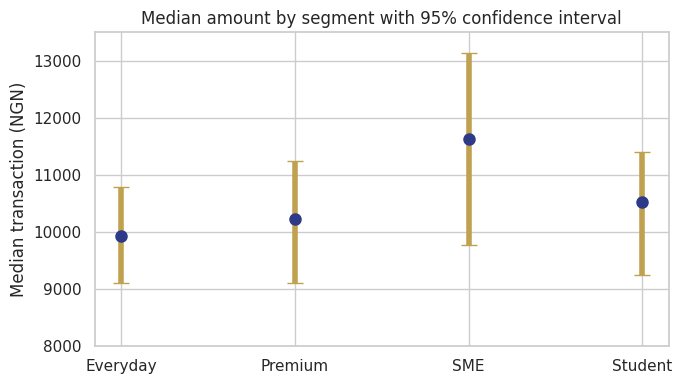

In [12]:
seg_order = ["Everyday", "Premium", "SME", "Student"]
rows = []
for s in seg_order:
    v = df[df.Customer_Segment == s].Amount_NGN.values
    boots = [np.median(rng.choice(v, len(v))) for _ in range(2000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append((s, len(v), np.median(v), lo, hi))
seg = pd.DataFrame(rows, columns=["Segment", "Tx", "Median", "CI low", "CI high"]).round(0)
print(seg.to_string(index=False))

p = df[df.Customer_Segment == "Premium"].Amount_NGN.values
o = df[df.Customer_Segment != "Premium"].Amount_NGN.values
gap = [np.median(rng.choice(p, len(p))) - np.median(rng.choice(o, len(o))) for _ in range(5000)]
gap_ci = np.percentile(gap, [2.5, 97.5])
kw = stats.kruskal(*[g.Amount_NGN.values for _, g in df.groupby("Customer_Segment")]).pvalue
print(f"\nMedian gap Premium minus others: {np.median(p) - np.median(o):.0f} NGN, 95% CI [{gap_ci[0]:.0f}, {gap_ci[1]:.0f}]")
print(f"Kruskal-Wallis p = {kw:.2f}")
R["v1"] = {"kruskal_p": round(float(kw), 2), "median_gap": round(float(np.median(p) - np.median(o)), 0),
           "gap_ci": [round(float(gap_ci[0]), 0), round(float(gap_ci[1]), 0)],
           "segments": seg.to_dict("records")}

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(seg.Segment, seg.Median, yerr=[seg.Median - seg["CI low"], seg["CI high"] - seg.Median],
            fmt="o", color=NAVY, ecolor=GOLD, elinewidth=4, capsize=6, markersize=8)
ax.set_ylabel("Median transaction (NGN)"); ax.set_xlabel("")
ax.set_title("Median amount by segment with 95% confidence interval")
ax.set_ylim(8000, 13500)
plt.tight_layout(); plt.savefig(FIG / "fig1_segment_median_ci.png", dpi=200); plt.show()

**Reading.** The confidence intervals overlap for all four segments and the Premium gap interval contains zero. The data does not show that Premium customers transact differently. The Week 3 revision of Finding 1 is confirmed.

## Part E. Validation 2: Mobile App reliability
**Finding to validate:** the Mobile App has the most failures in number, but a higher failure rate is not proven.
**New method:** Wilson 95% intervals, and a test of each channel against the rest with a correction for 5 comparisons (Bonferroni).

   Channel   Tx  Failed  Rate %  CI low  CI high  p vs rest  p corrected (x5)
Mobile App 5102     296   5.802   5.193    6.477      0.022             0.110
      USSD  889      48   5.399   4.096    7.086      0.897             1.000
       POS 2393     125   5.224   4.402    6.189      0.989             1.000
       Web 1869      88   4.708   3.837    5.765      0.277             1.000
       ATM 1747      73   4.179   3.336    5.222      0.035             0.173

Chi-square across the 5 channels: p = 0.081


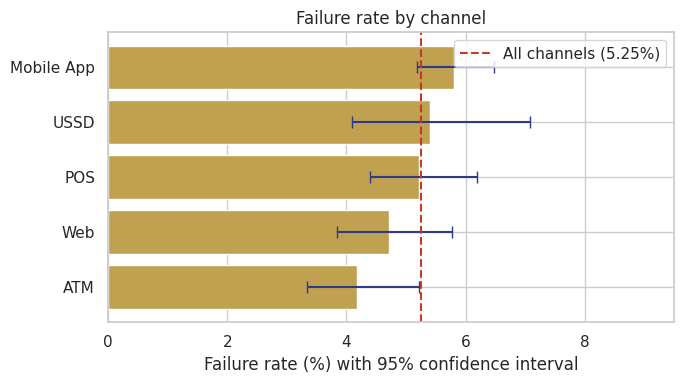

In [13]:
rows = []
for ch, g in df.groupby("Channel"):
    lo, hi = proportion_confint(g.failed.sum(), len(g), method="wilson")
    rest = df[df.Channel != ch]
    p_raw = stats.chi2_contingency(pd.crosstab(df.Channel == ch, df.failed))[1]
    rows.append((ch, len(g), int(g.failed.sum()), g.failed.mean() * 100, lo * 100, hi * 100, p_raw, min(p_raw * 5, 1)))
ch = pd.DataFrame(rows, columns=["Channel", "Tx", "Failed", "Rate %", "CI low", "CI high", "p vs rest", "p corrected (x5)"])
ch = ch.sort_values("Rate %", ascending=False).round(3)
print(ch.to_string(index=False))
p_all = stats.chi2_contingency(pd.crosstab(df.Channel, df.failed))[1]
print(f"\nChi-square across the 5 channels: p = {p_all:.3f}")
R["v2"] = {"chi2_p": round(float(p_all), 3), "channels": ch.to_dict("records")}

fig, ax = plt.subplots(figsize=(7, 4))
c2 = ch.sort_values("Rate %")
ax.barh(c2.Channel, c2["Rate %"], color=GOLD, xerr=[c2["Rate %"] - c2["CI low"], c2["CI high"] - c2["Rate %"]],
        ecolor=NAVY, capsize=4)
ax.axvline(df.failed.mean() * 100, color=RED, ls="--", label=f"All channels ({df.failed.mean()*100:.2f}%)")
ax.set_xlabel("Failure rate (%) with 95% confidence interval"); ax.set_xlim(0, 9.5); ax.legend(loc="upper right")
ax.set_title("Failure rate by channel")
plt.tight_layout(); plt.savefig(FIG / "fig2_channel_failure_ci.png", dpi=200); plt.show()

**Reading.** At the raw level two channels differ from the rest, the Mobile App (higher, p = 0.022) and the ATM (lower, p = 0.035). These comparisons were chosen after looking at the data. After the correction for 5 comparisons neither is significant (p = 0.11 and 0.17), and the five-channel test stays at p = 0.081. The Week 3 wording (most failures in number, higher rate not proven) is confirmed.

## Part E. Validation 3: Concentration of value
**Finding to validate:** a small share of transactions carries most of the value, and value is concentrated in a minority of customers.
**New method:** Gini coefficient and Lorenz curve, and an independent pandas recalculation of the SQL deciles.

{'top 10%': 25.86, 'top 20%': 43.57, 'top 30%': 57.81} | bottom 50%: 21.19
Gini of customer value: 0.404
High-value transactions (> 117,923 NGN): 1474 = 12.3% of the count, 62.5% of the value
Average / median = 4.53


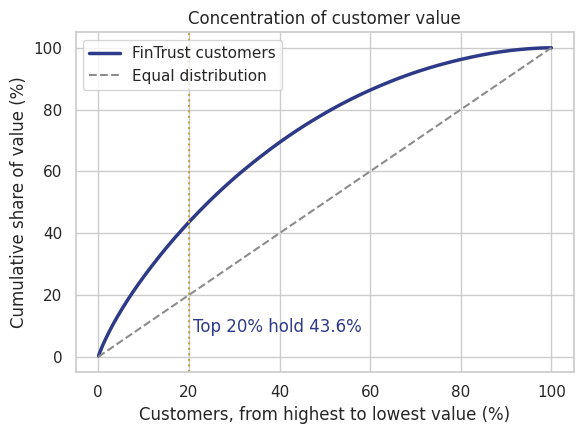

In [14]:
cv = df.groupby("Customer_ID").Amount_NGN.sum().sort_values(ascending=False)
cum = cv.cumsum() / cv.sum()
tops = {f"top {k}%": float(cum.iloc[int(len(cv) * k / 100) - 1] * 100) for k in (10, 20, 30)}
bottom50 = float(cv.iloc[len(cv) // 2:].sum() / cv.sum() * 100)

x = np.sort(cv.values)
gini = float((2 * np.arange(1, len(x) + 1) - len(x) - 1).dot(x) / (len(x) * x.sum()))
hv_count = df.high.mean() * 100
hv_value = df[df.high == 1].Amount_NGN.sum() / df.Amount_NGN.sum() * 100
print({k: round(v, 2) for k, v in tops.items()}, "| bottom 50%:", round(bottom50, 2))
print(f"Gini of customer value: {gini:.3f}")
print(f"High-value transactions (> {THR:,.0f} NGN): {int(df.high.sum())} = {hv_count:.1f}% of the count, {hv_value:.1f}% of the value")
print(f"Average / median = {df.Amount_NGN.mean() / df.Amount_NGN.median():.2f}")
R["v3"] = {**{k: round(v, 2) for k, v in tops.items()}, "bottom 50%": round(bottom50, 2), "gini": round(gini, 3),
           "high_count": int(df.high.sum()), "high_count_pct": round(float(hv_count), 1), "high_value_pct": round(float(hv_value), 1),
           "mean_median_ratio": round(float(df.Amount_NGN.mean() / df.Amount_NGN.median()), 2)}

share_cust = np.arange(1, len(cv) + 1) / len(cv) * 100
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(share_cust, cum.values * 100, color=NAVY, lw=2.5, label="FinTrust customers")
ax.plot([0, 100], [0, 100], color=GREY, ls="--", label="Equal distribution")
ax.axvline(20, color=GOLD, ls=":"); ax.text(21, 8, f"Top 20% hold {tops['top 20%']:.1f}%", color=NAVY)
ax.set_xlabel("Customers, from highest to lowest value (%)"); ax.set_ylabel("Cumulative share of value (%)")
ax.set_title("Concentration of customer value"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "fig3_value_concentration.png", dpi=200); plt.show()

**Reading.** The SQL deciles are reproduced exactly (top 20% = 43.57%, top 30% = 57.81%). The Gini coefficient shows a moderate concentration. The strong skew sits at transaction level (12.3% of transactions carry 62.5% of value), more than at customer level.

## Part E. Validation 4: What drives the risk-review flag
**Finding to validate:** the flag is linked to international status, high amounts, and the Transfer and Cash Withdrawal types, not to channel or segment.
**New method:** one logistic regression with all factors together (odds ratios), plus a cross-validated ROC-AUC to see how much the factors explain.

                           Odds ratio  CI low  CI high      p
International                   2.682   2.203    3.266  0.000
Type: Transfer                  2.455   2.154    2.799  0.000
Type: Cash Withdrawal           2.196   1.868    2.582  0.000
High amount (> threshold)       1.800   1.528    2.120  0.000
Type: Airtime/Data              1.273   1.049    1.547  0.015
Channel: ATM                    1.140   0.993    1.308  0.062
Channel: Web                    1.140   0.997    1.303  0.055
Type: Deposit                   1.128   0.937    1.357  0.205
Segment: Premium                1.050   0.929    1.188  0.434
Type: Bill Payment              1.038   0.861    1.252  0.692
Segment: Student                1.033   0.912    1.172  0.607
log10(amount)                   1.020   0.948    1.098  0.592
Segment: SME                    1.015   0.882    1.168  0.837
Channel: POS                    0.954   0.839    1.083  0.466
Channel: USSD                   0.874   0.721    1.058  0.166

5-fold 

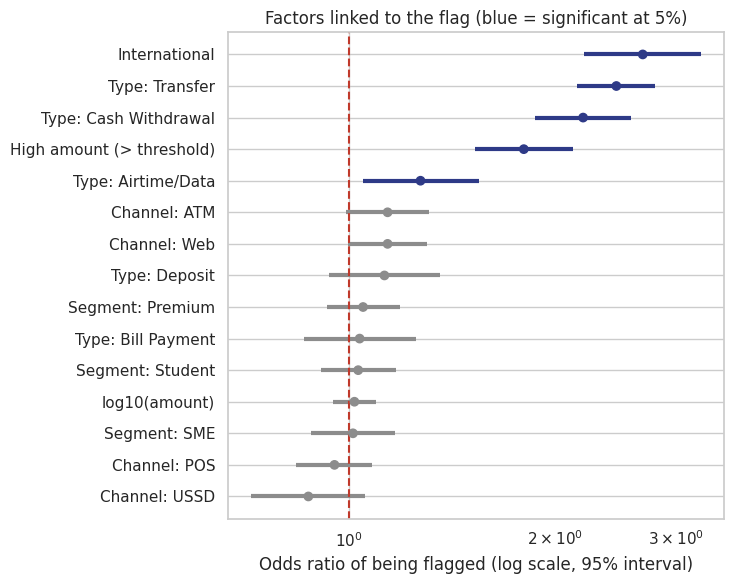

In [15]:
X = pd.get_dummies(df[["Transaction_Type", "Channel", "Customer_Segment"]]).astype(float)
X = X.drop(columns=["Transaction_Type_Card Purchase", "Channel_Mobile App", "Customer_Segment_Everyday"])
X["International"] = df.intl.values
X["High amount (> threshold)"] = df.high.values
X["log10(amount)"] = np.log10(df.Amount_NGN.values)
model = sm.Logit(df.flag.values, sm.add_constant(X)).fit(disp=0)
orr = pd.DataFrame({"Odds ratio": np.exp(model.params), "CI low": np.exp(model.conf_int()[0]),
                    "CI high": np.exp(model.conf_int()[1]), "p": model.pvalues}).drop(index="const").round(3)
orr.index = [i.replace("Transaction_Type_", "Type: ").replace("Channel_", "Channel: ").replace("Customer_Segment_", "Segment: ") for i in orr.index]
print(orr.sort_values("Odds ratio", ascending=False).to_string())

cv_auc = cross_val_score(LogisticRegression(max_iter=1000), X, df.flag, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"\n5-fold cross-validated ROC-AUC: {cv_auc.mean():.3f} (+/- {cv_auc.std():.3f})")
R["v4"] = {"odds_ratios": orr.reset_index().rename(columns={"index": "Factor"}).to_dict("records"),
           "cv_auc": round(float(cv_auc.mean()), 3)}

plot = orr.sort_values("Odds ratio")
fig, ax = plt.subplots(figsize=(7.5, 6))
colors = [NAVY if (p < 0.05) else GREY for p in plot.p]
ax.hlines(plot.index, plot["CI low"], plot["CI high"], color=colors, lw=3)
ax.scatter(plot["Odds ratio"], plot.index, color=colors, zorder=3)
ax.axvline(1, color=RED, ls="--"); ax.set_xscale("log")
ax.set_xlabel("Odds ratio of being flagged (log scale, 95% interval)")
ax.set_title("Factors linked to the flag (blue = significant at 5%)")
plt.tight_layout(); plt.savefig(FIG / "fig4_flag_odds_ratios.png", dpi=200); plt.show()

**Reading.** International status (odds about 2.7 times higher), Transfer (about 2.5), Cash Withdrawal (about 2.2) and the high-amount indicator (about 1.8) remain clearly linked to the flag when all factors are tested together. Segment has no effect, and channel effects are small and borderline. The amount itself (log scale) adds nothing once the high-amount threshold is in the model, so the effect is a jump above the threshold, not a gradual rise. A cross-validated AUC of about 0.64 shows these factors explain only part of the flag, which is what we would expect from a synthetic label.

## Part E. Validation 5: Declared preferences and account status versus behaviour
**Finding to validate:** `Preferred_Channel` and `Account_Status` do not describe what customers do.
**New method:** chi-square test of preferred versus actual channel, and activity of Dormant customers in the last 30 days.

Channel              ATM  Mobile App    POS  USSD    Web
Preferred_Channel                                       
Mobile App         14.52       42.46  20.08  7.40  15.55
USSD               15.39       41.75  20.23  7.52  15.10
Web                14.17       43.12  19.43  7.36  15.92

Chi-square p = 0.954, Cramer's V = 0.011 (0 = no link)
                customers  active_last_30_days   pct
Account_Status                                      
Active               1367                 1281  93.7
Dormant               107                   98  91.6
Restricted             26                   25  96.2

Transactions per customer: {'Active': 7.98, 'Dormant': 8.09, 'Restricted': 8.62}


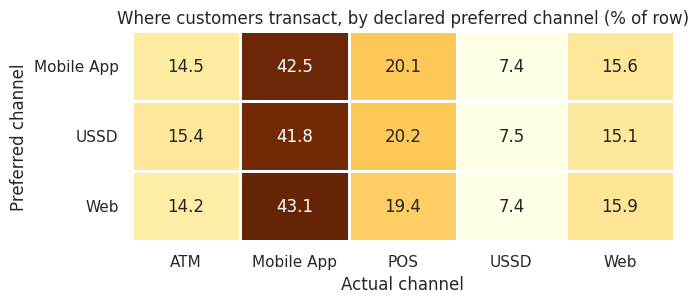

In [16]:
ctp = pd.crosstab(df.Preferred_Channel, df.Channel)
chi2, p_pref, dof, _ = stats.chi2_contingency(ctp)
cramers_v = np.sqrt(chi2 / (ctp.values.sum() * (min(ctp.shape) - 1)))
rowpct = (ctp.div(ctp.sum(axis=1), axis=0) * 100).round(2)
print(rowpct.to_string())
print(f"\nChi-square p = {p_pref:.3f}, Cramer's V = {cramers_v:.3f} (0 = no link)")

last = df.groupby("Customer_ID").Transaction_DateTime.max().rename("last_tx").reset_index().merge(cust[["Customer_ID", "Account_Status"]])
last["recent"] = (last.last_tx >= "2026-03-02").astype(int)
status = last.groupby("Account_Status").agg(customers=("recent", "size"), active_last_30_days=("recent", "sum"))
status["pct"] = (status.active_last_30_days / status.customers * 100).round(1)
print(status.to_string())
tpc = df.groupby("Account_Status").size() / cust.groupby("Account_Status").size()
print("\nTransactions per customer:", tpc.round(2).to_dict())
R["v5"] = {"chi2_p": round(float(p_pref), 3), "cramers_v": round(float(cramers_v), 3),
           "row_pct": rowpct.reset_index().to_dict("records"), "status": status.reset_index().to_dict("records"),
           "tx_per_customer_by_status": {k: round(float(v), 2) for k, v in tpc.items()}}

fig, ax = plt.subplots(figsize=(7, 3.2))
sns.heatmap(rowpct[["ATM", "Mobile App", "POS", "USSD", "Web"]], annot=True, fmt=".1f", cmap="YlOrBr", cbar=False, ax=ax, linewidths=1)
ax.set_title("Where customers transact, by declared preferred channel (% of row)")
ax.set_xlabel("Actual channel"); ax.set_ylabel("Preferred channel"); plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.savefig(FIG / "fig5_preferred_vs_actual.png", dpi=200); plt.show()

**Reading.** The three rows of the heatmap are almost identical (p = 0.95, Cramer's V close to zero). A customer who declares USSD makes 41.8% of transactions on the Mobile App and only 7.5% on USSD. Dormant customers are as active as the others (91.6% had a transaction in the last 30 days). Finding 6 is confirmed.

## Part E. Validation 6: Regularity of the time pattern
**Finding to validate:** activity is flat (about 133 transactions per day) and no growth, seasonality or peak hour can be read from this data.
**New method:** chi-square test against a perfectly uniform pattern, by hour, weekday and day.

In [17]:
per_day = df.groupby(df.Transaction_DateTime.dt.date).size()
per_hour = df.groupby(df.Transaction_DateTime.dt.hour).size()
per_dow = df.groupby(df.Transaction_DateTime.dt.dayofweek).size()
print("Transactions per day: min", per_day.min(), "max", per_day.max(), "mean", round(per_day.mean(), 2))
print("Transactions per hour: min", per_hour.min(), "max", per_hour.max())
print("Per weekday:", per_dow.to_dict())
print("Per-day rate by month:", (df.groupby(df.Transaction_DateTime.dt.month).size() / [31, 28, 31]).round(2).to_dict())
p_hour = stats.chisquare(per_hour).pvalue
print(f"Chi-square test of uniform hours: p = {p_hour:.2f}")
monthly_flag_p = stats.chi2_contingency(pd.crosstab(df.Transaction_DateTime.dt.month, df.flag))[1]
print(f"Flag rate by month: p = {monthly_flag_p:.2f}")
R["v6"] = {"per_day_min": int(per_day.min()), "per_day_max": int(per_day.max()), "per_hour_min": int(per_hour.min()),
           "per_hour_max": int(per_hour.max()), "p_hour": round(float(p_hour), 2), "monthly_flag_p": round(float(monthly_flag_p), 2)}

Transactions per day: min 133 max 134 mean 133.33
Transactions per hour: min 500 max 500
Per weekday: {0: 1732, 1: 1733, 2: 1602, 3: 1733, 4: 1732, 5: 1734, 6: 1734}
Per-day rate by month: {1: 133.32, 2: 133.36, 3: 133.32}
Chi-square test of uniform hours: p = 1.00
Flag rate by month: p = 0.10


**Reading.** Every hour has exactly 500 transactions and every day 133 or 134. Real banking activity is never this regular, so this is a limitation of the synthetic data. No statement on peak hours, growth or seasonality can be made. The small change in flag rate by month (18.5%, 20.3%, 20.1%) is not significant (p = 0.10).

## Summary of the findings after Weeks 3 and 4

| Finding | Result after Week 3 | Result after Week 4 validation |
|---|---|---|
| 1. Premium has the lowest transaction value | **Revised:** segments behave similarly (Chart 1) | Confirmed with bootstrap intervals (Validation 1) |
| 2. Mobile App is the most valuable and least reliable channel | **Nuanced:** most failures in number, rates close (Chart 2) | Confirmed. After correction for 5 comparisons, p = 0.11 (Validation 2) |
| 3. Transfer and Card Purchase are over half of activity | Confirmed (54.9%, SQL analysis) | Confirmed in the final SQL and in Insight 6 of the report |
| 4. Flagging follows an explainable pattern | **Confirmed and extended** with transaction type (Charts 4 and 5) | Confirmed with a regression. Channel effect is small and borderline (Validation 4) |
| 5. Amounts are skewed with a long tail of large values | Confirmed (average 46,706 versus median 10,306) | Confirmed. 12.3% of transactions carry 62.5% of value (Validation 3) |
| 6. Preferred channel and account status do not match behaviour | Confirmed (Week 3) | Confirmed (Validation 5) |

## Limitations
- The data is synthetic, so patterns are simpler and more regular than real banking data (flat daily activity, exactly 500 transactions per hour).
- Only 3 months of data: no growth or seasonality can be measured.
- There are few international transactions (480), so international results are less precise.
- `Device_Type` and `Location` do not match the channel or the customer's city, so they are not used.

## Part A. Reproducibility check and export of the results

In [18]:
def key_numbers(d):
    return (len(d), round(d.Amount_NGN.sum(), 2), round(d.Amount_NGN.median(), 2), round(d.ok.mean(), 6), round(d.flag.mean(), 6))

first = key_numbers(df)
reloaded = pd.read_csv(DATA / "FinTrust_Transaction_Data_Clean.csv", parse_dates=["Transaction_DateTime"]).merge(cust, on="Customer_ID")
reloaded["ok"] = (reloaded.Transaction_Status == "Successful").astype(int)
reloaded["flag"] = (reloaded.Risk_Review_Flag == "Yes").astype(int)
second = key_numbers(reloaded)
print("First run :", first); print("Second run:", second)
assert first == second
R["reproducibility"] = {"first": first, "second": second, "identical": first == second}

with open(DOCS / "validation_results.json", "w") as f:
    json.dump(R, f, indent=2, default=str)
print("\nResults saved to docs/validation_results.json")

First run : (12000, np.float64(560477354.85), np.float64(10305.94), np.float64(0.904667), np.float64(0.196))
Second run: (12000, np.float64(560477354.85), np.float64(10305.94), np.float64(0.904667), np.float64(0.196))

Results saved to docs/validation_results.json
